# Marketing Campaign A/B/n Analysis
**Question:** Did the new promotion actually drive more sales, or is the difference just luck?

**Approach:** hypothesis testing at a 95% confidence level (α = 0.05), effect sizes with confidence intervals, multiple-comparison control, robustness checks, and a rollout projection.

> **Dataset note.** The supplied file (`WA_Marketing-Campaign.csv`) is the *fast-food promotion* experiment: three promotions (1, 2, 3) tested in 137 stores for 4 weeks each, with **weekly sales (in $ thousands)** as the outcome. It has no per-user purchase flag, so a user-level *conversion rate* cannot be computed from it. The outcome here is therefore a **continuous metric (sales)**, tested with Welch's t-test / ANOVA instead of a z-test on proportions. For the binary-conversion version of this task (Kaggle *Marketing A/B Testing*: ad vs PSA), see `src/conversion_ab_test.py`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import TTestIndPower

ALPHA, SEED, N_BOOT = 0.05, 42, 10_000
rng = np.random.default_rng(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
COL = {1: "#1b6ca8", 2: "#8a8a8a", 3: "#d9822b"}      # colour-blind-safe, one colour per promotion
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})

## 1. Data loading and quality checks

In [2]:
raw = pd.read_csv(ROOT / "data" / "WA_Marketing-Campaign.csv")
print("shape:", raw.shape)
print("missing values:", int(raw.isna().sum().sum()), "| duplicate rows:", int(raw.duplicated().sum()))
print("negative sales:", int((raw.SalesInThousands < 0).sum()))
print("weeks:", sorted(raw.week.unique()), "| promotions:", sorted(raw.Promotion.unique()))
# each store must receive exactly one promotion for the whole test (clean between-store design)
print("max promotions per store:", raw.groupby("LocationID").Promotion.nunique().max())
print("rows per store:", raw.groupby("LocationID").size().unique())
raw.head()

shape: (548, 7)
missing values: 0 | duplicate rows: 0
negative sales: 0
weeks: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)] | promotions: [np.int64(1), np.int64(2), np.int64(3)]
max promotions per store: 1
rows per store: [4]


,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
0,1,Medium,1,4,3,1,33.73
1,1,Medium,1,4,3,2,35.67
2,1,Medium,1,4,3,3,29.03
3,1,Medium,1,4,3,4,39.25
4,1,Medium,2,5,2,1,27.81


## 2. Experimental design and unit of analysis
Every store ran **one** promotion for **4 weeks**, so the 548 rows are 137 stores × 4 weeks. Weekly rows from the same store are strongly correlated; treating them as 548 independent observations (*pseudo-replication*) would shrink standard errors and inflate significance. The **store is the experimental unit**, so we average each store's 4 weeks and test on **137 independent observations**.

In [3]:
stores = (raw.groupby(["LocationID", "Promotion", "MarketSize"], as_index=False)
             .agg(sales=("SalesInThousands", "mean"), age=("AgeOfStore", "first")))
n_by = stores.groupby("Promotion").size()
print(n_by.to_string())
bal = pd.crosstab(stores.Promotion, stores.MarketSize)
print("\nStores by market size:\n", bal)
chi2, p, *_ = stats.chi2_contingency(bal)
print(f"\nBalance check (promotion x market size): chi2={chi2:.2f}, p={p:.3f}")
print("Age of store by promotion (ANOVA):", stats.f_oneway(*[g.age for _, g in stores.groupby("Promotion")]))

Promotion
1    43
2    47
3    47

Stores by market size:
 MarketSize  Large  Medium  Small
Promotion                       
1              14      24      5
2              16      27      4
3              12      29      6

Balance check (promotion x market size): chi2=1.19, p=0.880
Age of store by promotion (ANOVA): F_onewayResult(statistic=np.float64(0.44986464971900764), pvalue=np.float64(0.6386740228229728))


Market size is a strong driver of sales (see below). Allocation is reasonably balanced across promotions, but not perfect, so we also run a **covariate-adjusted** model as a robustness check.

## 3. Descriptive statistics

,n,mean,sd,median,se,ci95_low,ci95_high
Promotion,,,,,,,
1,43,58.10,16.03,56.08,2.44,53.17,63.03
2,47,47.33,14.50,46.66,2.11,43.07,51.59
3,47,55.36,16.38,49.85,2.39,50.55,60.17


Promotion      1     2     3
MarketSize                  
Large       75.2  60.3  77.2
Medium      47.7  39.1  45.5
Small       60.2  50.8  59.5


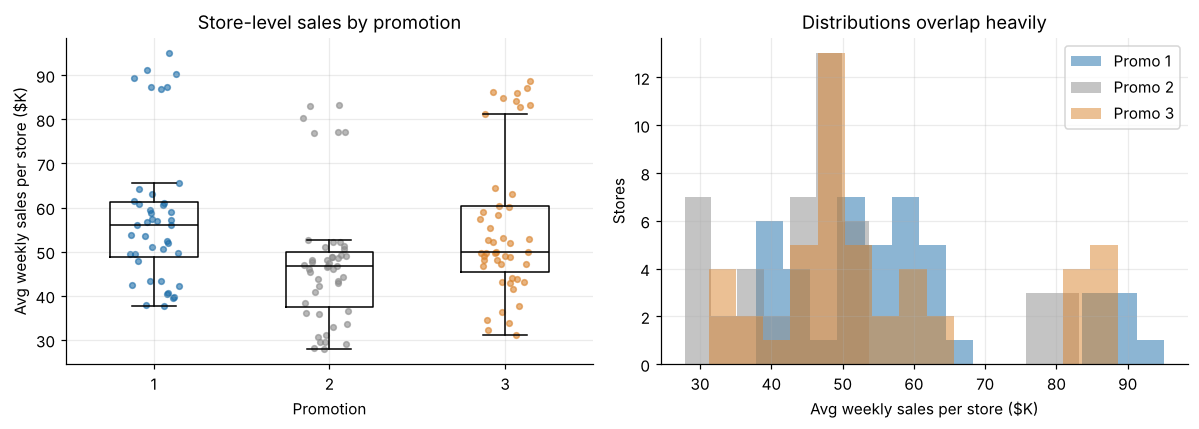

In [4]:
desc = stores.groupby("Promotion").sales.agg(n="count", mean="mean", sd="std", median="median")
desc["se"] = desc.sd / np.sqrt(desc.n)
tcrit = stats.t.ppf(1 - ALPHA/2, desc.n - 1)
desc["ci95_low"], desc["ci95_high"] = desc["mean"] - tcrit*desc["se"], desc["mean"] + tcrit*desc["se"]
display(desc.round(2))
print(stores.groupby(["MarketSize", "Promotion"]).sales.mean().unstack().round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k in (1, 2, 3):
    v = stores.loc[stores.Promotion == k, "sales"]
    ax[0].boxplot(v, positions=[k], widths=.5, showfliers=False, medianprops=dict(color="k"))
    ax[0].scatter(k + rng.uniform(-.15, .15, len(v)), v, s=14, alpha=.6, color=COL[k])
ax[0].set(xticks=[1, 2, 3], xlabel="Promotion", ylabel="Avg weekly sales per store ($K)", title="Store-level sales by promotion")
for k in (1, 2, 3):
    ax[1].hist(stores.loc[stores.Promotion == k, "sales"], bins=15, alpha=.5, color=COL[k], label=f"Promo {k}")
ax[1].set(xlabel="Avg weekly sales per store ($K)", ylabel="Stores", title="Distributions overlap heavily"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "01_sales_distribution.png", bbox_inches="tight"); plt.show()

## 4. Hypothesis tests
**Omnibus test** — H₀: all three promotions have the same mean store sales; H₁: at least one differs.

In [5]:
groups = [g.sales.values for _, g in stores.groupby("Promotion")]
print("Normality (Shapiro) per promo p-values:", [round(stats.shapiro(g).pvalue, 3) for g in groups])
print("Equal variance (Levene) p =", round(stats.levene(*groups).pvalue, 3))
F, pF = stats.f_oneway(*groups)
H, pH = stats.kruskal(*groups)
print(f"One-way ANOVA : F = {F:.2f}, p = {pF:.4f}")
print(f"Kruskal-Wallis: H = {H:.2f}, p = {pH:.4f}   (non-parametric check)")

Normality (Shapiro) per promo p-values: [np.float64(0.0), np.float64(0.0), np.float64(0.0)]
Equal variance (Levene) p = 0.627
One-way ANOVA : F = 5.85, p = 0.0037
Kruskal-Wallis: H = 17.33, p = 0.0002   (non-parametric check)


**Pairwise tests** — Welch's t-test (does not assume equal variances) for each pair. Because we make 3 comparisons, p-values are adjusted with the **Holm** procedure to keep the family-wise error rate at 5%. Significance is judged on the *adjusted* p-value.

In [6]:
def boot_lift(a, b, n=N_BOOT):
    ia, ib = rng.integers(0, len(a), (n, len(a))), rng.integers(0, len(b), (n, len(b)))
    r = a[ia].mean(1) / b[ib].mean(1) - 1
    return np.percentile(r, [100*ALPHA/2, 100*(1-ALPHA/2)])

S = {k: stores.loc[stores.Promotion == k, "sales"].values for k in (1, 2, 3)}
rows = []
for a, b in [(1, 2), (3, 2), (1, 3)]:                      # a is the "treatment", b the comparison
    x, y = S[a], S[b]
    t, p = stats.ttest_ind(x, y, equal_var=False)
    vx, vy = x.var(ddof=1)/len(x), y.var(ddof=1)/len(y)
    se = np.sqrt(vx + vy); df = se**4 / (vx**2/(len(x)-1) + vy**2/(len(y)-1))
    d = x.mean() - y.mean(); h = stats.t.ppf(1-ALPHA/2, df)*se
    sp = np.sqrt(((len(x)-1)*x.var(ddof=1) + (len(y)-1)*y.var(ddof=1)) / (len(x)+len(y)-2))
    lo, hi = boot_lift(x, y)
    rows.append(dict(comparison=f"Promo {a} vs {b}", diff_K=d, diff_ci_low=d-h, diff_ci_high=d+h,
                     lift_pct=100*(x.mean()/y.mean()-1), lift_ci_low=100*lo, lift_ci_high=100*hi,
                     t=t, p_raw=p, mannwhitney_p=stats.mannwhitneyu(x, y).pvalue, cohens_d=d/sp, a=a, b=b))
pw = pd.DataFrame(rows)
pw["p_holm"] = multipletests(pw.p_raw, method="holm")[1]
pw["significant_95"] = pw.p_holm < ALPHA
pw.drop(columns=["a", "b"]).round(4).set_index("comparison")

,diff_K,diff_ci_low,diff_ci_high,lift_pct,lift_ci_low,lift_ci_high,t,p_raw,mannwhitney_p,cohens_d,p_holm,significant_95
comparison,,,,,,,,,,,,
Promo 1 vs 2,10.7696,4.3434,17.1958,22.7546,8.7023,38.3874,3.3321,0.0013,0.0001,0.7063,0.0038,True
Promo 3 vs 2,8.0351,1.6961,14.3740,16.9769,3.6181,31.9556,2.5180,0.0136,0.0025,0.5194,0.0271,True
Promo 1 vs 3,2.7345,-4.0593,9.5284,4.9392,-6.4790,18.2888,0.7999,0.4259,0.1773,0.1686,0.4259,False


## 5. Robustness checks

In [7]:
# (a) Permutation test on the omnibus F statistic - no distributional assumptions
obs = stats.f_oneway(*groups).statistic
lab = stores.Promotion.values; y = stores.sales.values
perm = np.array([stats.f_oneway(*[y[p == k] for k in (1, 2, 3)]).statistic
                 for p in (rng.permutation(lab) for _ in range(5000))])
print(f"(a) Permutation test on ANOVA F: p = {(perm >= obs).mean():.4f}")

# (b) Covariate-adjusted model on store-level data (reference = Promo 2)
m1 = smf.ols("sales ~ C(Promotion, Treatment(2)) + C(MarketSize) + age", stores).fit(cov_type="HC3")
print("\n(b) OLS adjusted for market size & store age (HC3 robust SE):")
print(m1.summary().tables[1])

# (c) Weekly data with cluster-robust SEs by store (uses all 548 rows, respects dependence)
m2 = smf.ols("SalesInThousands ~ C(Promotion, Treatment(2)) + C(MarketSize)", raw).fit(
    cov_type="cluster", cov_kwds={"groups": raw.LocationID})
print("\n(c) Weekly data, store-clustered SEs:")
print(m2.summary().tables[1])

# (d) Naive test that ignores store clustering - shown only to illustrate the inflation
r = raw.SalesInThousands
naive = stats.ttest_ind(r[raw.Promotion == 1], r[raw.Promotion == 2], equal_var=False).pvalue
print(f"\n(d) NAIVE row-level Promo1 vs Promo2 p = {naive:.2g}  vs store-level p = {pw.p_raw[0]:.2g} (store-level is the valid one)")

(a) Permutation test on ANOVA F: p = 0.0020

(b) OLS adjusted for market size & store age (HC3 robust SE):
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept                          63.2612      2.794     22.645      0.000      57.786      68.737
C(Promotion, Treatment(2))[T.1]    10.7521      2.252      4.775      0.000       6.338      15.166
C(Promotion, Treatment(2))[T.3]     9.6782      2.143      4.517      0.000       5.479      13.878
C(MarketSize)[T.Medium]           -26.6327      2.545    -10.464      0.000     -31.621     -21.644
C(MarketSize)[T.Small]            -14.0727      2.572     -5.472      0.000     -19.113      -9.032
age                                 0.0709      0.124      0.573      0.567      -0.172       0.313

(c) Weekly data, store-clustered SEs:
                                      coef    std err 

## 6. Visualising the lift with 95% confidence intervals
Lift = (mean sales of promotion ÷ mean sales of comparison) − 1. Intervals are percentile bootstrap (10,000 resamples of stores). A bar whose interval excludes 0% is statistically distinguishable from no effect.

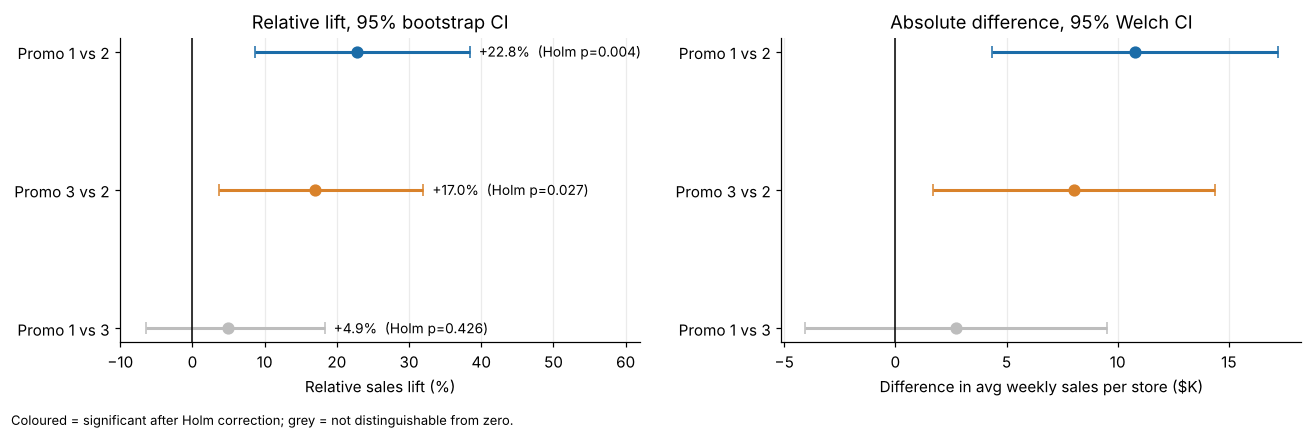

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
order = pw.iloc[::-1].reset_index(drop=True)
for i, r in order.iterrows():
    c = COL[int(r.a)] if r.significant_95 else "#bdbdbd"
    ax[0].errorbar(r.lift_pct, i, xerr=[[r.lift_pct-r.lift_ci_low], [r.lift_ci_high-r.lift_pct]],
                   fmt="o", color=c, ecolor=c, capsize=4, lw=2, ms=7)
    ax[0].annotate(f"{r.lift_pct:+.1f}%  (Holm p={r.p_holm:.3f})", (r.lift_ci_high, i), xytext=(6, 0),
                   textcoords="offset points", va="center", fontsize=9)
ax[0].axvline(0, color="k", lw=1)
ax[0].set(yticks=range(len(order)), yticklabels=order.comparison, xlabel="Relative sales lift (%)",
          title="Relative lift, 95% bootstrap CI", xlim=(-10, 62)); ax[0].grid(axis="y", alpha=0)
for i, r in order.iterrows():
    c = COL[int(r.a)] if r.significant_95 else "#bdbdbd"
    ax[1].errorbar(r.diff_K, i, xerr=[[r.diff_K-r.diff_ci_low], [r.diff_ci_high-r.diff_K]],
                   fmt="o", color=c, ecolor=c, capsize=4, lw=2, ms=7)
ax[1].axvline(0, color="k", lw=1)
ax[1].set(yticks=range(len(order)), yticklabels=order.comparison, xlabel="Difference in avg weekly sales per store ($K)",
          title="Absolute difference, 95% Welch CI"); ax[1].grid(axis="y", alpha=0)
fig.text(.01, -.03, "Coloured = significant after Holm correction; grey = not distinguishable from zero.", fontsize=8.5)
plt.tight_layout(); plt.savefig(FIG / "02_lift_confidence_intervals.png", bbox_inches="tight"); plt.show()

## 7. Business impact: rollout to 100% of stores (bonus)
Scenario: the chain adopts promotion *A* in **every** store instead of promotion *B*. Expected incremental sales = (difference in mean weekly sales per store) × (number of stores). The dataset has no customer counts, so impact is expressed in **sales ($K)**. The annualised figure is an *illustrative linear extrapolation* of a 4-week test (ignores seasonality and novelty effects).

Stores in rollout: 137


,significant_95,weekly_chain_K,annual_chain_K,weekly_chain_ci_low,annual_chain_ci_low,weekly_chain_ci_high,annual_chain_ci_high
comparison,,,,,,,
Promo 1 vs 2,True,1475.0,76723.0,595.0,30942.0,2356.0,122503.0
Promo 3 vs 2,True,1101.0,57242.0,232.0,12083.0,1969.0,102401.0
Promo 1 vs 3,False,375.0,19481.0,-556.0,-28919.0,1305.0,67881.0


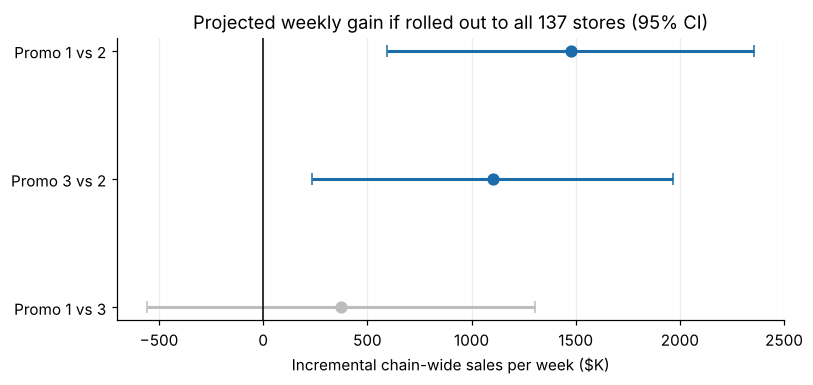

In [9]:
N_STORES = stores.LocationID.nunique()
imp = pw[["comparison", "diff_K", "diff_ci_low", "diff_ci_high", "significant_95"]].copy()
for c in ("diff_K", "diff_ci_low", "diff_ci_high"):
    imp[c.replace("diff", "weekly_chain")] = imp[c] * N_STORES
    imp[c.replace("diff", "annual_chain")] = imp[c] * N_STORES * 52
imp = imp.drop(columns=["diff_K", "diff_ci_low", "diff_ci_high"]).set_index("comparison")
print(f"Stores in rollout: {N_STORES}")
display(imp.round(0))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, (name, r) in enumerate(imp.iloc[::-1].iterrows()):
    c = "#1b6ca8" if r.significant_95 else "#bdbdbd"
    ax.errorbar(r.weekly_chain_K, i, xerr=[[r.weekly_chain_K-r.weekly_chain_ci_low], [r.weekly_chain_ci_high-r.weekly_chain_K]],
                fmt="o", color=c, ecolor=c, capsize=4, lw=2, ms=7)
ax.axvline(0, color="k", lw=1)
ax.set(yticks=range(3), yticklabels=imp.index[::-1], xlabel="Incremental chain-wide sales per week ($K)",
       title=f"Projected weekly gain if rolled out to all {N_STORES} stores (95% CI)"); ax.grid(axis="y", alpha=0)
plt.tight_layout(); plt.savefig(FIG / "03_rollout_projection.png", bbox_inches="tight"); plt.show()

## 8. Power: can we tell Promo 1 and Promo 3 apart?
Promo 1 vs 3 is not significant. "Not significant" is not "no difference": it may simply mean the test was too small to detect a modest gap.

In [10]:
a = pw.loc[pw.comparison == "Promo 1 vs 3"].iloc[0]
pa = TTestIndPower()
pw_now = pa.power(abs(a.cohens_d), nobs1=len(S[1]), alpha=ALPHA, ratio=len(S[3])/len(S[1]))
n_need = pa.solve_power(effect_size=abs(a.cohens_d), power=.8, alpha=ALPHA)
mde = pa.solve_power(nobs1=len(S[1]), power=.8, alpha=ALPHA, ratio=len(S[3])/len(S[1])) * np.sqrt(np.mean([S[k].var(ddof=1) for k in (1, 3)]))
print(f"Observed effect size (Cohen's d) = {a.cohens_d:.2f}; power at current sample sizes = {pw_now:.0%}")
print(f"Stores per group needed to confirm that gap with 80% power: {int(np.ceil(n_need))}")
print(f"Minimum detectable difference (80% power, current n) ~ ${mde:.1f}K per store per week")

Observed effect size (Cohen's d) = 0.17; power at current sample sizes = 12%
Stores per group needed to confirm that gap with 80% power: 553
Minimum detectable difference (80% power, current n) ~ $9.7K per store per week


## 9. Conclusions

In [11]:
from IPython.display import Markdown
g = lambda c: pw.set_index("comparison").loc[c]
out = f'''
| Comparison | Lift | Diff ($K/store/wk) [95% CI] | Holm-adj. p | Verdict |
|---|---|---|---|---|
'''
for c, r in pw.set_index("comparison").iterrows():
    out += f"| {c} | {r.lift_pct:+.1f}% | {r.diff_K:+.1f} [{r.diff_ci_low:+.1f}, {r.diff_ci_high:+.1f}] | {r.p_holm:.4f} | {'Significant' if r.significant_95 else 'Not significant'} |\n"
Markdown(out)


| Comparison | Lift | Diff ($K/store/wk) [95% CI] | Holm-adj. p | Verdict |
|---|---|---|---|---|
| Promo 1 vs 2 | +22.8% | +10.8 [+4.3, +17.2] | 0.0038 | Significant |
| Promo 3 vs 2 | +17.0% | +8.0 [+1.7, +14.4] | 0.0271 | Significant |
| Promo 1 vs 3 | +4.9% | +2.7 [-4.1, +9.5] | 0.4259 | Not significant |


* The omnibus tests (ANOVA, Kruskal-Wallis, permutation) reject "all promotions perform the same" at the 95% level, so the differences are **not luck**.
* **Promotions 1 and 3 both significantly outperform Promotion 2** (the weakest) after multiple-comparison correction; the result is robust to the choice of test, to adjusting for market size and store age, and to clustering by store.
* **Promotion 1 vs 3 is inconclusive**: the test cannot distinguish them, and it was under-powered for a gap that small. Choosing between them needs either a larger test or non-sales considerations (cost, margin, operational complexity).
* **Limitations:** only 4 weeks; stores were not randomised within market size (adjusted models mitigate this); sales are a proxy for customer purchases; the rollout projection assumes the effect persists and scales linearly.

## 10. Export results

In [12]:
pw.drop(columns=["a", "b"]).to_csv(ROOT / "reports" / "pairwise_results.csv", index=False)
imp.to_csv(ROOT / "reports" / "rollout_projection.csv")
desc.to_csv(ROOT / "reports" / "descriptive_stats.csv")
print("Saved:", sorted(p.name for p in (ROOT / "reports").glob("*.csv")), sorted(p.name for p in FIG.glob("*.png")))

Saved: ['descriptive_stats.csv', 'pairwise_results.csv', 'rollout_projection.csv'] ['01_sales_distribution.png', '02_lift_confidence_intervals.png', '03_rollout_projection.png']
